In [1]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

In [3]:
## Data preparation
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
df.head().T

,0,1,2,3,4
lead_source,organic_search,social_media,referral,paid_ads,referral
industry,technology,technology,retail,manufacturing,manufacturing
employment_status,employed,employed,employed,student,student
location,europe,south_america,europe,NaN,north_america
annual_income,88160.0,72688.0,44697.0,NaN,24062.0
number_of_courses_viewed,3,3,3,3,4
interaction_count,4,7,4,6,5
lead_score,0.64,0.72,0.58,0.57,0.62
converted,1,1,1,0,1


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [6]:
## missing variables
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [7]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']

In [8]:
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

In [9]:
for c in categorical:
    df[c] = df[c].fillna('NaN')

In [10]:
for c in numerical:
    df[c] = df[c].fillna('0')

In [11]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [12]:
## Question 1 - mode
df.industry.info

<bound method Series.info of 0          technology
1          technology
2              retail
3       manufacturing
4       manufacturing
            ...      
4995        education
4996       technology
4997          finance
4998       technology
4999       technology
Name: industry, Length: 5000, dtype: str>

In [13]:
df['industry'].value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NaN               240
Name: count, dtype: int64

In [14]:
## Question 2 - correlation matrix
corr_matrix = df[numerical].corr()
print(corr_matrix)

                          annual_income  number_of_courses_viewed  \
annual_income                  1.000000                  0.161300   
number_of_courses_viewed       0.161300                  1.000000   
interaction_count              0.122842                  0.721609   
lead_score                     0.229496                  0.757204   

                          interaction_count  lead_score  
annual_income                      0.122842    0.229496  
number_of_courses_viewed           0.721609    0.757204  
interaction_count                  1.000000    0.915746  
lead_score                         0.915746    1.000000  


<Axes: >

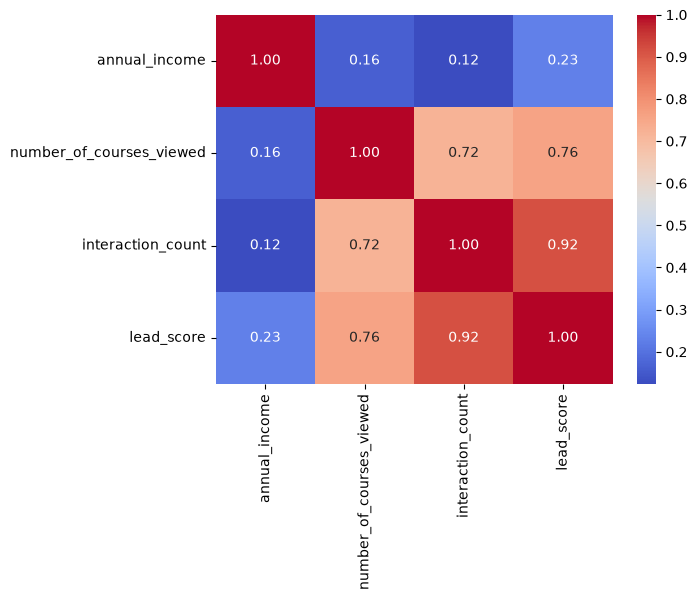

In [15]:
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')

In [16]:
## Question 3
## Setting up the validation framework
from sklearn.model_selection import train_test_split

In [17]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

In [18]:
len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [19]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [20]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [21]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [22]:
df_full_train = df_full_train.reset_index(drop=True)

In [23]:
df_full_train.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [24]:
## Mutual information
from sklearn.metrics import mutual_info_score

In [25]:
def mutual_info_churn_score(series):
    return mutual_info_score(series, df_full_train.converted)

In [26]:
score = df_full_train[categorical].apply(mutual_info_churn_score)
mi = round(score, 2)
mi.sort_values(ascending=False)

lead_source          0.03
employment_status    0.02
industry             0.00
location             0.00
dtype: float64

In [27]:
## Question 4 - model training
## one-hot encoding
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [28]:
#fit model on training
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [29]:
# accuracy on validation dataset
model.intercept_[0]

np.float64(-0.010832463318570957)

In [30]:
model.coef_[0].round(3)

array([-0.   , -0.003, -0.001,  0.007, -0.003, -0.008, -0.006, -0.   ,
       -0.003, -0.001, -0.002, -0.002, -0.002, -0.001,  0.137,  0.011,
       -0.001,  0.   , -0.009,  0.007, -0.014,  0.009, -0.004,  0.   ,
       -0.002, -0.002, -0.001, -0.003, -0.004,  0.054])

In [31]:
y_pred = model.predict_proba(X_val)[:, 1]

In [32]:
convert_decision = (y_pred >= 0.5)

In [33]:
(y_val == convert_decision).mean()

np.float64(0.645)

In [34]:
df_pred = pd.DataFrame()
df_pred['probability'] = y_pred
df_pred['prediction'] = convert_decision.astype(int)
df_pred['actual'] = y_val

In [35]:
df_pred['correct'] = df_pred.prediction == df_pred.actual

In [39]:
baseline_correct = df_pred.correct.mean()

In [43]:
## Question 5 - feature elimination

features = categorical + numerical

results = []

for feature in features:

    selected_features = [f for f in features if f != feature]

    train_dict = df_train[selected_features].to_dict(orient='records')
    val_dict = df_val[selected_features].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)

    X_train = dv.fit_transform(train_dict)
    X_val = dv.transform(val_dict)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    convert_decision = (y_pred >= 0.5)
    (y_val == convert_decision).mean()

    df_pred = pd.DataFrame()
    df_pred['probability'] = y_pred
    df_pred['prediction'] = convert_decision.astype(int)
    df_pred['actual'] = y_val

    df_pred['correct'] = df_pred.prediction == df_pred.actual
    y_correct = df_pred.correct.mean()

    results.append({
        'excluded_feature': feature,
        'correct_difference': baseline_correct - y_correct
    })
    

In [44]:
print(results)

[{'excluded_feature': 'lead_source', 'correct_difference': np.float64(0.0030000000000000027)}, {'excluded_feature': 'industry', 'correct_difference': np.float64(0.0)}, {'excluded_feature': 'employment_status', 'correct_difference': np.float64(0.0)}, {'excluded_feature': 'location', 'correct_difference': np.float64(0.0)}, {'excluded_feature': 'annual_income', 'correct_difference': np.float64(-0.08199999999999996)}, {'excluded_feature': 'number_of_courses_viewed', 'correct_difference': np.float64(0.0020000000000000018)}, {'excluded_feature': 'interaction_count', 'correct_difference': np.float64(0.04500000000000004)}, {'excluded_feature': 'lead_score', 'correct_difference': np.float64(0.0010000000000000009)}]


In [49]:
## Question 6 - regularisation
C_values = [0.000001, 0.00001, 0.0001, 0.001]

accuracy = []

for C in C_values:
    model = LogisticRegression(
        C=C,
        max_iter=1000,
        solver='liblinear', random_state=42
    )

    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    convert_decision = (y_pred >= 0.5)
    (y_val == convert_decision).mean()

    df_pred = pd.DataFrame()
    df_pred['probability'] = y_pred
    df_pred['prediction'] = convert_decision.astype(int)
    df_pred['actual'] = y_val

    df_pred['correct'] = df_pred.prediction == df_pred.actual
    y_correct = df_pred.correct.mean().round(3)

    accuracy.append({
        'C_values': C,
        'accuracy': y_correct
    })




In [48]:
print(accuracy)

[{'C_values': 1e-06, 'accuracy': np.float64(0.598)}, {'C_values': 1e-05, 'accuracy': np.float64(0.598)}, {'C_values': 0.0001, 'accuracy': np.float64(0.613)}, {'C_values': 0.001, 'accuracy': np.float64(0.644)}]
